# Segment 3: Machines with Breakdowns (Interrupts)

## Overview

In real manufacturing systems, machines don't run perfectly - they break down. When a machine fails during production, the current job is interrupted and must resume after repair. This segment introduces **PreemptiveResource** and **Interrupts** in SimPy.

## The Problem

A manufacturing machine processes jobs. While processing a job:
- The machine might randomly break down
- The job is interrupted mid-processing
- Machine must be repaired (takes time)
- Job resumes where it left off

**Key Questions:**
- How do breakdowns affect job completion times?
- What's the impact of Mean Time Between Failures (MTBF)?
- How do we model jobs resuming after interruption?

## New SimPy Concepts

### PreemptiveResource

A `PreemptiveResource` allows higher-priority requests to **interrupt** lower-priority ones.

In [ ]:
# Run this cell first.
# In the browser (JupyterLite) it installs the extra packages into this tab;
# in Colab or Anaconda it installs them with pip (already installed = no change).
%pip install simpy

```python
machine = simpy.PreemptiveResource(env, capacity=1)

# Lower number = higher priority
with machine.request(priority=1) as req:  # Normal job
    yield req
    # Work...

with machine.request(priority=0, preempt=True) as req:  # Breakdown (interrupts jobs)
    yield req
    # Repair...
```

### Handling Interrupts

When a process is interrupted, it receives a `simpy.Interrupt` exception:

```python
try:
    yield env.timeout(10)  # Try to work
except simpy.Interrupt:
    print("Got interrupted!")
    # Handle the interruption
```

## Building the Simulation

### Complete Code

> **Correction (erratum C2).** In the original notes, a job that a breakdown interrupts carries on *inside* the same `with machine.request()` block. By then it has lost the machine, so it keeps working during the repair, and two jobs can run at once on a one-machine resource. The `job` function below queues for the machine again after each interrupt, as the Week 04 emergency-department model does. With the fix, the cheapest MTBF in the cost analysis is **20 h** ($89,181), not 15 h ($53,804). The original text is kept in `5 Source Files/Notes (Markdown)`.

In [2]:
import simpy
import random
import matplotlib.pyplot as plt

# Data collection
job_completion_times = []
job_interruptions = []
total_interruptions = 0

def machine_breakdown_process(env, machine, mtbf, mttr):
    """
    Randomly breaks the machine down.
    
    Args:
        mtbf: Mean Time Between Failures (hours)
        mttr: Mean Time To Repair (hours)
    """
    global total_interruptions
    
    while True:
        # Work for some time before breaking
        uptime = random.expovariate(1.0 / mtbf)
        yield env.timeout(uptime)
        
        print(f"{env.now:.2f}: ⚠️  MACHINE BREAKDOWN!")
        total_interruptions += 1
        
        # Request machine with highest priority to "seize" it for repairs
        with machine.request(priority=-1, preempt=True) as req:
            yield req
            
            # Repair the machine
            repair_time = random.expovariate(1.0 / mttr)
            yield env.timeout(repair_time)
            
            print(f"{env.now:.2f}: ✓  Machine repaired (took {repair_time:.2f} hours)")

def job(env, name, machine, processing_time):
    """
    A job that uses the machine and can be interrupted.
    
    Args:
        processing_time: Total time needed to complete the job
    """
    print(f"{env.now:.2f}: {name} arrives (needs {processing_time:.2f} hours)")
    
    arrival_time = env.now
    interruption_count = 0
    remaining_time = processing_time
    
    # Keep trying to complete the job. After a breakdown the job has lost the machine,
    # so it must queue for it again (corrected: the original kept working without the machine).
    while remaining_time > 0:
        with machine.request(priority=1) as req:
            yield req
            print(f"{env.now:.2f}: {name} working (needs {remaining_time:.2f} more hours)")

            try:
                # Try to complete remaining work
                start_time = env.now
                yield env.timeout(remaining_time)

                # Success! Job completed
                completion_time = env.now - arrival_time
                job_completion_times.append(completion_time)
                job_interruptions.append(interruption_count)

                print(f"{env.now:.2f}: {name} COMPLETED (total time: {completion_time:.2f} hours, interruptions: {interruption_count})")
                remaining_time = 0

            except simpy.Interrupt as interrupt:
                # Machine broke down! Record the work done, then queue again
                work_done = env.now - start_time
                remaining_time -= work_done
                interruption_count += 1

                print(f"{env.now:.2f}: {name} INTERRUPTED (completed {work_done:.2f} hours, {remaining_time:.2f} hours remaining)")

def job_generator(env, machine, arrival_rate, processing_time_mean):
    """Generate jobs arriving at the machine."""
    
    job_number = 0
    while True:
        # Wait for next job
        yield env.timeout(random.expovariate(arrival_rate))
        
        job_number += 1
        processing_time = random.expovariate(1.0 / processing_time_mean)
        env.process(job(env, f"Job {job_number}", machine, processing_time))

def run_simulation(mtbf, mttr, sim_time=200, arrival_rate=0.1, processing_time=5.0, random_seed=42):
    """Run simulation with specified breakdown parameters."""
    
    # Reset globals
    global job_completion_times, job_interruptions, total_interruptions
    job_completion_times = []
    job_interruptions = []
    total_interruptions = 0
    
    # Setup
    random.seed(random_seed)
    env = simpy.Environment()
    machine = simpy.PreemptiveResource(env, capacity=1)
    
    # Start processes
    env.process(machine_breakdown_process(env, machine, mtbf, mttr))
    env.process(job_generator(env, machine, arrival_rate, processing_time))
    
    # Run
    print("="*70)
    print(f"Simulation: MTBF={mtbf}h, MTTR={mttr}h")
    print("="*70)
    env.run(until=sim_time)
    
    # Return statistics
    return {
        'mtbf': mtbf,
        'mttr': mttr,
        'jobs_completed': len(job_completion_times),
        'avg_completion_time': sum(job_completion_times) / len(job_completion_times) if job_completion_times else 0,
        'max_completion_time': max(job_completion_times) if job_completion_times else 0,
        'avg_interruptions': sum(job_interruptions) / len(job_interruptions) if job_interruptions else 0,
        'total_breakdowns': total_interruptions
    }

# Run baseline: No breakdowns (MTBF = very high)
print("\n" + "="*70)
print("BASELINE: No Breakdowns")
print("="*70)
baseline = run_simulation(mtbf=10000, mttr=1, sim_time=200)

print(f"\nJobs completed: {baseline['jobs_completed']}")
print(f"Average completion time: {baseline['avg_completion_time']:.2f} hours")
print(f"Maximum completion time: {baseline['max_completion_time']:.2f} hours")

# Run with moderate breakdowns
print("\n" + "="*70)
print("SCENARIO 1: Moderate Reliability (MTBF=50h)")
print("="*70)
scenario1 = run_simulation(mtbf=50, mttr=5, sim_time=200)

print(f"\nJobs completed: {scenario1['jobs_completed']}")
print(f"Average completion time: {scenario1['avg_completion_time']:.2f} hours")
print(f"Maximum completion time: {scenario1['max_completion_time']:.2f} hours")
print(f"Average interruptions per job: {scenario1['avg_interruptions']:.2f}")
print(f"Total breakdowns: {scenario1['total_breakdowns']}")

# Run with frequent breakdowns
print("\n" + "="*70)
print("SCENARIO 2: Poor Reliability (MTBF=20h)")
print("="*70)
scenario2 = run_simulation(mtbf=20, mttr=5, sim_time=200)

print(f"\nJobs completed: {scenario2['jobs_completed']}")
print(f"Average completion time: {scenario2['avg_completion_time']:.2f} hours")
print(f"Maximum completion time: {scenario2['max_completion_time']:.2f} hours")
print(f"Average interruptions per job: {scenario2['avg_interruptions']:.2f}")
print(f"Total breakdowns: {scenario2['total_breakdowns']}")


BASELINE: No Breakdowns
Simulation: MTBF=10000h, MTTR=1h
0.25: Job 1 arrives (needs 1.61 hours)
0.25: Job 1 working (needs 1.61 more hours)
1.86: Job 1 COMPLETED (total time: 1.61 hours, interruptions: 0)
2.78: Job 2 arrives (needs 6.67 hours)
2.78: Job 2 working (needs 6.67 more hours)
9.45: Job 2 COMPLETED (total time: 6.67 hours, interruptions: 0)
14.07: Job 3 arrives (needs 11.14 hours)
14.07: Job 3 working (needs 11.14 more hours)
14.98: Job 4 arrives (needs 2.74 hours)
15.28: Job 5 arrives (needs 1.23 hours)
22.32: Job 6 arrives (needs 0.13 hours)
24.54: Job 7 arrives (needs 5.25 hours)
25.21: Job 3 COMPLETED (total time: 11.14 hours, interruptions: 0)
25.21: Job 4 working (needs 2.74 more hours)
27.95: Job 4 COMPLETED (total time: 12.97 hours, interruptions: 0)
27.95: Job 5 working (needs 1.23 more hours)
29.18: Job 5 COMPLETED (total time: 13.90 hours, interruptions: 0)
29.18: Job 6 working (needs 0.13 more hours)
29.32: Job 6 COMPLETED (total time: 6.99 hours, interruptions: 

## Analyzing the Impact of Breakdowns

### Comparing Scenarios

In [3]:
# Compare different MTBF values
mtbf_values = [10000, 100, 50, 30, 20, 15]  # Decreasing reliability
results = []

print("\n" + "="*70)
print("COMPARING DIFFERENT RELIABILITY LEVELS")
print("="*70)

for mtbf in mtbf_values:
    stats = run_simulation(mtbf=mtbf, mttr=5, sim_time=200, random_seed=42)
    results.append(stats)
    
    print(f"\nMTBF={mtbf}h:")
    print(f"  Jobs completed: {stats['jobs_completed']}")
    print(f"  Avg completion time: {stats['avg_completion_time']:.2f}h")
    print(f"  Avg interruptions: {stats['avg_interruptions']:.2f}")


COMPARING DIFFERENT RELIABILITY LEVELS
Simulation: MTBF=10000h, MTTR=5h
0.25: Job 1 arrives (needs 1.61 hours)
0.25: Job 1 working (needs 1.61 more hours)
1.86: Job 1 COMPLETED (total time: 1.61 hours, interruptions: 0)
2.78: Job 2 arrives (needs 6.67 hours)
2.78: Job 2 working (needs 6.67 more hours)
9.45: Job 2 COMPLETED (total time: 6.67 hours, interruptions: 0)
14.07: Job 3 arrives (needs 11.14 hours)
14.07: Job 3 working (needs 11.14 more hours)
14.98: Job 4 arrives (needs 2.74 hours)
15.28: Job 5 arrives (needs 1.23 hours)
22.32: Job 6 arrives (needs 0.13 hours)
24.54: Job 7 arrives (needs 5.25 hours)
25.21: Job 3 COMPLETED (total time: 11.14 hours, interruptions: 0)
25.21: Job 4 working (needs 2.74 more hours)
27.95: Job 4 COMPLETED (total time: 12.97 hours, interruptions: 0)
27.95: Job 5 working (needs 1.23 more hours)
29.18: Job 5 COMPLETED (total time: 13.90 hours, interruptions: 0)
29.18: Job 6 working (needs 0.13 more hours)
29.32: Job 6 COMPLETED (total time: 6.99 hours, 

### Visualization

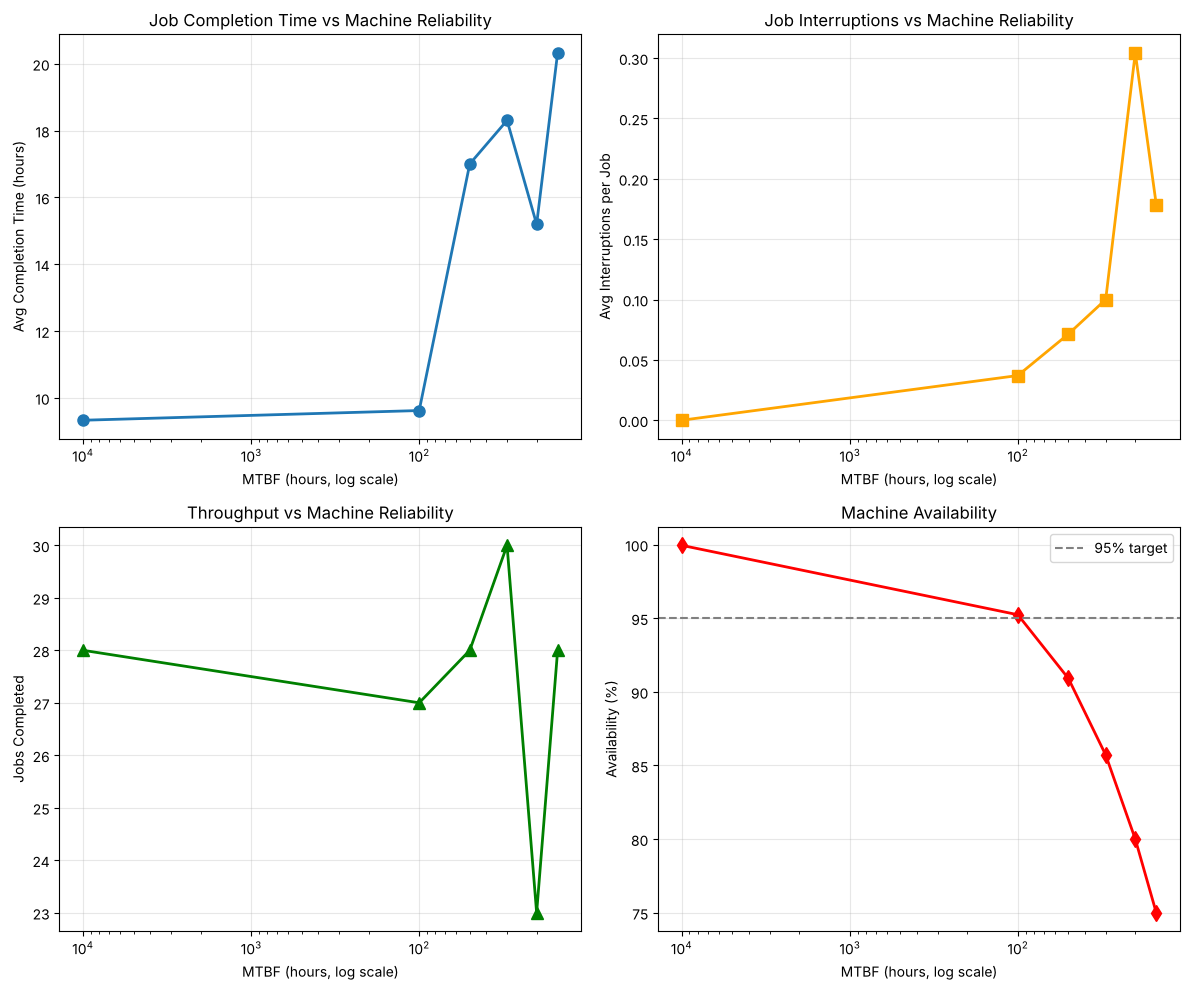

In [4]:
# Extract data
mtbf_vals = [r['mtbf'] for r in results]
avg_times = [r['avg_completion_time'] for r in results]
avg_interrupts = [r['avg_interruptions'] for r in results]
jobs_done = [r['jobs_completed'] for r in results]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Plot 1: Completion time vs reliability
axes[0, 0].semilogx(mtbf_vals, avg_times, marker='o', linewidth=2, markersize=8)
axes[0, 0].set_xlabel('MTBF (hours, log scale)')
axes[0, 0].set_ylabel('Avg Completion Time (hours)')
axes[0, 0].set_title('Job Completion Time vs Machine Reliability')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].invert_xaxis()  # Higher MTBF (better) on the right

# Plot 2: Interruptions vs reliability
axes[0, 1].semilogx(mtbf_vals, avg_interrupts, marker='s', linewidth=2, markersize=8, color='orange')
axes[0, 1].set_xlabel('MTBF (hours, log scale)')
axes[0, 1].set_ylabel('Avg Interruptions per Job')
axes[0, 1].set_title('Job Interruptions vs Machine Reliability')
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].invert_xaxis()

# Plot 3: Throughput vs reliability
axes[1, 0].semilogx(mtbf_vals, jobs_done, marker='^', linewidth=2, markersize=8, color='green')
axes[1, 0].set_xlabel('MTBF (hours, log scale)')
axes[1, 0].set_ylabel('Jobs Completed')
axes[1, 0].set_title('Throughput vs Machine Reliability')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].invert_xaxis()

# Plot 4: Availability
# Availability = MTBF / (MTBF + MTTR)
mttr = 5
availabilities = [100 * mtbf / (mtbf + mttr) for mtbf in mtbf_vals]

axes[1, 1].semilogx(mtbf_vals, availabilities, marker='d', linewidth=2, markersize=8, color='red')
axes[1, 1].set_xlabel('MTBF (hours, log scale)')
axes[1, 1].set_ylabel('Availability (%)')
axes[1, 1].set_title('Machine Availability')
axes[1, 1].axhline(y=95, color='gray', linestyle='--', label='95% target')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].invert_xaxis()

plt.tight_layout()
plt.show()

## Understanding Reliability Metrics

### Key Concepts

**MTBF (Mean Time Between Failures)**
- Average time the machine runs before breaking down
- Higher MTBF = more reliable
- Example: MTBF = 50 hours means average of 50 hours between failures

**MTTR (Mean Time To Repair)**
- Average time to fix the machine after breakdown
- Lower MTTR = faster repairs
- Example: MTTR = 5 hours means average repair takes 5 hours

**Availability**
- Percentage of time machine is operational
- Formula: A = MTBF / (MTBF + MTTR)
- Example: MTBF=50, MTTR=5 → A = 50/55 = 90.9%

### Impact on Performance

```
High Reliability (MTBF=100h, MTTR=5h)
├─ Availability: 95.2%
├─ Few interruptions
├─ Jobs complete close to expected time
└─ Predictable production

Low Reliability (MTBF=20h, MTTR=5h)
├─ Availability: 80%
├─ Frequent interruptions
├─ Jobs take much longer
└─ Unpredictable production
```

## Maintenance Strategies

### Preventive vs Reactive Maintenance

**Reactive (Run to Failure)**
- Wait for breakdowns, then repair
- What we simulated above
- Lower maintenance cost, higher downtime cost

**Preventive (Scheduled Maintenance)**
- Regular maintenance before failures
- Prevents breakdowns but costs time/money
- Trade-off to optimize

### Modeling Preventive Maintenance

In [5]:
def preventive_maintenance_process(env, machine, maintenance_interval, maintenance_time):
    """Perform scheduled maintenance."""
    
    while True:
        # Wait for maintenance interval
        yield env.timeout(maintenance_interval)
        
        print(f"{env.now:.2f}: Scheduled maintenance starting")
        
        # Request machine for maintenance
        with machine.request(priority=0) as req:  # Higher priority than jobs
            yield req
            yield env.timeout(maintenance_time)
            print(f"{env.now:.2f}: Maintenance complete")

# To add to simulation:
# env.process(preventive_maintenance_process(env, machine, interval=100, time=2))

**Question for students:** How do you find the optimal maintenance interval?

## Cost Analysis with Breakdowns

### Operating Costs Model

This is where **reliability trade-offs** become critical. A more reliable machine costs more upfront and to maintain, but saves money through fewer breakdowns.

In [6]:
import numpy as np

def calculate_total_cost_of_ownership(stats, mtbf, processing_time_mean=5.0, sim_time=200):
    """
    Calculate Total Cost of Ownership including:
    - Capital investment in reliability
    - Maintenance programs
    - Breakdown repair costs
    - Production losses from downtime and delays
    """
    
    # 1. CAPITAL COST - More reliable machines are more expensive
    # Model: Cost inversely related to MTBF
    # A machine with MTBF=100h might cost $50,000
    # A machine with MTBF=20h might cost $20,000
    base_cost = 20000  # Baseline cheap machine
    reliability_multiplier = mtbf / 20  # More reliable = expensive
    capital_cost = base_cost * reliability_multiplier
    
    # 2. PREVENTIVE MAINTENANCE COST
    # Better maintenance programs reduce breakdowns but cost money
    # More reliable machines have lower preventive maintenance needs
    if mtbf >= 100:
        preventive_maintenance_cost = 500  # Minimal maintenance
    elif mtbf >= 50:
        preventive_maintenance_cost = 2000  # Moderate maintenance
    elif mtbf >= 30:
        preventive_maintenance_cost = 5000  # Intensive maintenance
    else:
        preventive_maintenance_cost = 8000  # Frequent maintenance needed
    
    # 3. REACTIVE MAINTENANCE COST - Fix breakdowns as they occur
    breakdown_repair_cost = stats['total_breakdowns'] * 800  # $800 per repair call
    
    # 4. DOWNTIME COSTS - Production losses
    
    # 4a. Delay costs (customers unhappy with late delivery)
    expected_completion = processing_time_mean
    actual_completion = stats['avg_completion_time']
    delay = max(0, actual_completion - expected_completion)
    delay_cost_per_hour = 150  # $150 per hour of delay (customer penalties)
    total_delay_cost = stats['jobs_completed'] * delay * delay_cost_per_hour
    
    # 4b. Lost production (fewer jobs completed due to breakdowns)
    baseline_jobs = int(sim_time / processing_time_mean * 0.8)  # Expected jobs without breakdowns
    lost_jobs = max(0, baseline_jobs - stats['jobs_completed'])
    lost_profit_per_job = 2000  # $2000 profit if job completed
    lost_production_revenue = lost_jobs * lost_profit_per_job
    
    # 5. AVAILABILITY BONUS - If you maintain high availability, you can charge more
    # Availability = MTBF / (MTBF + MTTR)
    mttr = 5  # Assume standard repair time
    availability = mtbf / (mtbf + mttr)
    availability_bonus = 0
    if availability >= 0.95:
        availability_bonus = 10000  # Premium customers pay extra for 95%+ availability
    elif availability >= 0.90:
        availability_bonus = 5000
    
    # TOTAL COST OF OWNERSHIP
    total_cost = (capital_cost + preventive_maintenance_cost + 
                  breakdown_repair_cost + total_delay_cost + lost_production_revenue 
                  - availability_bonus)
    
    return {
        'capital_cost': capital_cost,
        'preventive_maintenance': preventive_maintenance_cost,
        'repair_cost': breakdown_repair_cost,
        'delay_cost': total_delay_cost,
        'lost_production': lost_production_revenue,
        'availability_bonus': availability_bonus,
        'total_cost': total_cost,
        'availability': availability * 100
    }

# Calculate costs for each scenario
print("\n" + "="*70)
print("TOTAL COST OF OWNERSHIP ANALYSIS")
print("="*70)

cost_results = []
for stats in results:
    mtbf = stats['mtbf']
    costs = calculate_total_cost_of_ownership(stats, mtbf)
    cost_results.append(costs)
    
    print(f"\n{'─'*70}")
    print(f"MTBF = {mtbf}h (Availability: {costs['availability']:.1f}%)")
    print(f"{'─'*70}")
    print(f"  Capital cost:              ${costs['capital_cost']:>12,.0f}")
    print(f"  Preventive maintenance:    ${costs['preventive_maintenance']:>12,.0f}")
    print(f"  Reactive repairs:          ${costs['repair_cost']:>12,.0f}")
    print(f"  Customer delay costs:      ${costs['delay_cost']:>12,.0f}")
    print(f"  Lost production:           ${costs['lost_production']:>12,.0f}")
    print(f"  Availability bonus:       -${costs['availability_bonus']:>12,.0f}")
    print(f"  {'─'*50}")
    print(f"  TOTAL COST:                ${costs['total_cost']:>12,.0f}")

# Find optimal
min_cost_idx = np.argmin([c['total_cost'] for c in cost_results])
optimal_mtbf = results[min_cost_idx]['mtbf']
optimal_cost = cost_results[min_cost_idx]['total_cost']

print(f"\n" + "="*70)
print(f"🎯 OPTIMAL CHOICE: MTBF = {optimal_mtbf}h")
print(f"   Total Cost of Ownership: ${optimal_cost:,.0f}")
print(f"="*70)


TOTAL COST OF OWNERSHIP ANALYSIS

──────────────────────────────────────────────────────────────────────
MTBF = 10000h (Availability: 100.0%)
──────────────────────────────────────────────────────────────────────
  Capital cost:              $  10,000,000
  Preventive maintenance:    $         500
  Reactive repairs:          $           0
  Customer delay costs:      $      18,191
  Lost production:           $       8,000
  Availability bonus:       -$      10,000
  ──────────────────────────────────────────────────
  TOTAL COST:                $  10,016,691

──────────────────────────────────────────────────────────────────────
MTBF = 100h (Availability: 95.2%)
──────────────────────────────────────────────────────────────────────
  Capital cost:              $     100,000
  Preventive maintenance:    $         500
  Reactive repairs:          $       1,600
  Customer delay costs:      $      18,718
  Lost production:           $      10,000
  Availability bonus:       -$      10,0

### Visualization of Cost Trade-offs

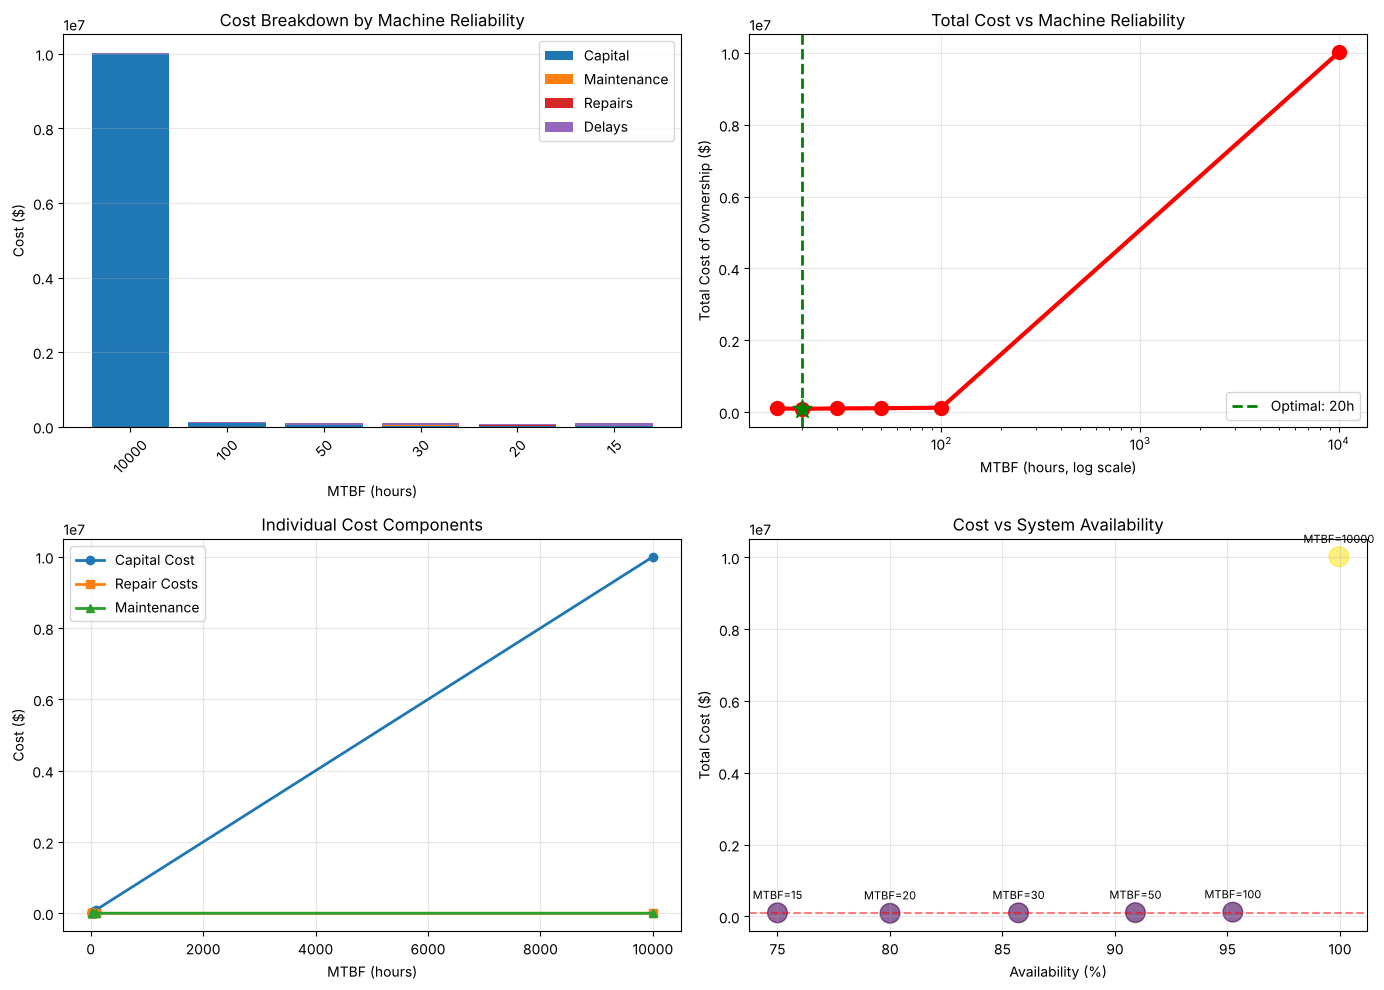


KEY INSIGHT: The cheapest machine isn't always the best choice!
Sometimes a mid-range machine optimizes total cost of ownership.


In [7]:
import numpy as np

# Extract cost data
mtbf_vals = [r['mtbf'] for r in results]
capital = [c['capital_cost'] for c in cost_results]
maintenance = [c['preventive_maintenance'] for c in cost_results]
repairs = [c['repair_cost'] for c in cost_results]
delays = [c['delay_cost'] for c in cost_results]
losses = [c['lost_production'] for c in cost_results]
total_costs = [c['total_cost'] for c in cost_results]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Cost breakdown (stacked bar chart)
x_pos = np.arange(len(mtbf_vals))
axes[0, 0].bar(x_pos, capital, label='Capital', color='#1f77b4')
axes[0, 0].bar(x_pos, maintenance, bottom=capital, label='Maintenance', color='#ff7f0e')
axes[0, 0].bar(x_pos, repairs, bottom=np.array(capital)+np.array(maintenance), 
               label='Repairs', color='#d62728')
delay_bottom = np.array(capital) + np.array(maintenance) + np.array(repairs)
axes[0, 0].bar(x_pos, delays, bottom=delay_bottom, label='Delays', color='#9467bd')
axes[0, 0].set_xlabel('MTBF (hours)')
axes[0, 0].set_ylabel('Cost ($)')
axes[0, 0].set_title('Cost Breakdown by Machine Reliability')
axes[0, 0].set_xticks(x_pos)
axes[0, 0].set_xticklabels([f"{m}" for m in mtbf_vals], rotation=45)
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3, axis='y')

# Plot 2: Total cost curve
axes[0, 1].plot(mtbf_vals, total_costs, marker='o', linewidth=3, markersize=10, color='red')
axes[0, 1].axvline(optimal_mtbf, color='green', linestyle='--', linewidth=2, label=f'Optimal: {optimal_mtbf}h')
axes[0, 1].scatter([optimal_mtbf], [optimal_cost], color='green', s=200, zorder=5, marker='*')
axes[0, 1].set_xlabel('MTBF (hours, log scale)')
axes[0, 1].set_ylabel('Total Cost of Ownership ($)')
axes[0, 1].set_title('Total Cost vs Machine Reliability')
axes[0, 1].set_xscale('log')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Individual cost components
axes[1, 0].plot(mtbf_vals, capital, marker='o', label='Capital Cost', linewidth=2)
axes[1, 0].plot(mtbf_vals, repairs, marker='s', label='Repair Costs', linewidth=2)
axes[1, 0].plot(mtbf_vals, maintenance, marker='^', label='Maintenance', linewidth=2)
axes[1, 0].set_xlabel('MTBF (hours)')
axes[1, 0].set_ylabel('Cost ($)')
axes[1, 0].set_title('Individual Cost Components')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Plot 4: Availability vs Total Cost
availabilities = [c['availability'] for c in cost_results]
axes[1, 1].scatter(availabilities, total_costs, s=200, alpha=0.6, c=mtbf_vals, cmap='viridis')
axes[1, 1].axhline(optimal_cost, color='red', linestyle='--', alpha=0.5)
axes[1, 1].set_xlabel('Availability (%)')
axes[1, 1].set_ylabel('Total Cost ($)')
axes[1, 1].set_title('Cost vs System Availability')
axes[1, 1].grid(True, alpha=0.3)
# Add labels for each point
for i, mtbf in enumerate(mtbf_vals):
    axes[1, 1].annotate(f'MTBF={mtbf}', 
                        (availabilities[i], total_costs[i]),
                        textcoords="offset points", xytext=(0,10), ha='center', fontsize=8)

plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("KEY INSIGHT: The cheapest machine isn't always the best choice!")
print("Sometimes a mid-range machine optimizes total cost of ownership.")
print("="*70)

## Real-World Applications

### Manufacturing
- Assembly lines where stations can break
- CNC machines that require maintenance
- Conveyor systems with mechanical failures

### Transportation
- Buses/trains that break down mid-route
- Delivery vehicles requiring repairs
- Airport equipment failures

### Healthcare
- Medical equipment (MRI, CT scanners) needing maintenance
- Operating rooms with equipment failures
- Lab equipment breakdowns

### IT Systems
- Servers that crash during processing
- Network equipment failures
- Database systems requiring restarts

## Key Takeaways

1. **PreemptiveResource** allows interruptions (priority-based)
2. **Lower priority number = higher priority** (-1 highest)
3. **Try-except** blocks handle interrupts gracefully
4. **Jobs track remaining work** and resume after interruption
5. **Breakdowns significantly impact** completion times and throughput
6. **Availability** = MTBF / (MTBF + MTTR) is key metric
7. **Cost analysis** reveals impact of reliability on business

## Discussion Questions

1. At what MTBF does the system become unacceptably unreliable?
2. Is it better to have fast repairs (low MTTR) or fewer failures (high MTBF)?
3. How would you decide between preventive and reactive maintenance?
4. What if repairs take variable time (some failures worse than others)?
5. How would you model a system with backup machines?

## Extension Exercises

1. **Add preventive maintenance**
   - Scheduled every X hours
   - Reduces breakdown probability
   - Find optimal maintenance schedule

2. **Model spare parts**
   - Repairs faster if parts in stock
   - Inventory holding costs vs delay costs

3. **Multiple machines**
   - Jobs can use any available machine
   - One breakdown doesn't stop all production

4. **Priority jobs**
   - Some jobs more important than others
   - How to schedule when breakdowns occur?

---

**Next:** Segment 4 - Hospital Optimization (Hands-On Exercise)